# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p13"
subproj <- "AVGUSTINOVA_24_25"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "RPS8"     "MAP2"     "CADM2"    "ADGRL3"   "ANK2"     "PDE4D"   
 [7] "EBF1"     "RPS18"    "KCNQ5"    "EEF1A1"   "RPS12"    "CACNA2D1"
[13] "IMMP2L"   "DGKI"     "CNTNAP2"  "ADAMTSL1" "RPS6"     "VIM"     
[19] "NEBL"     "ATRNL1"   "MALAT1"   "RPL41"    "HMGA2"    "ENOX1"   
[25] "RAD51B"   "RPLP1"    "RPL13A"   "MIR99AHG" "MID1"     "RPL10"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))

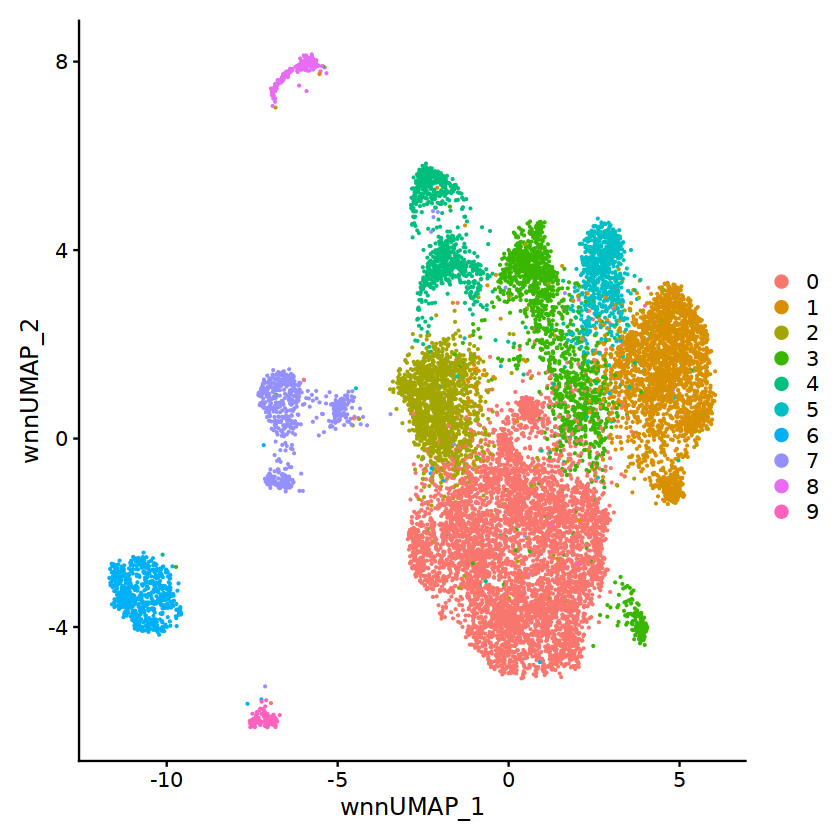

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

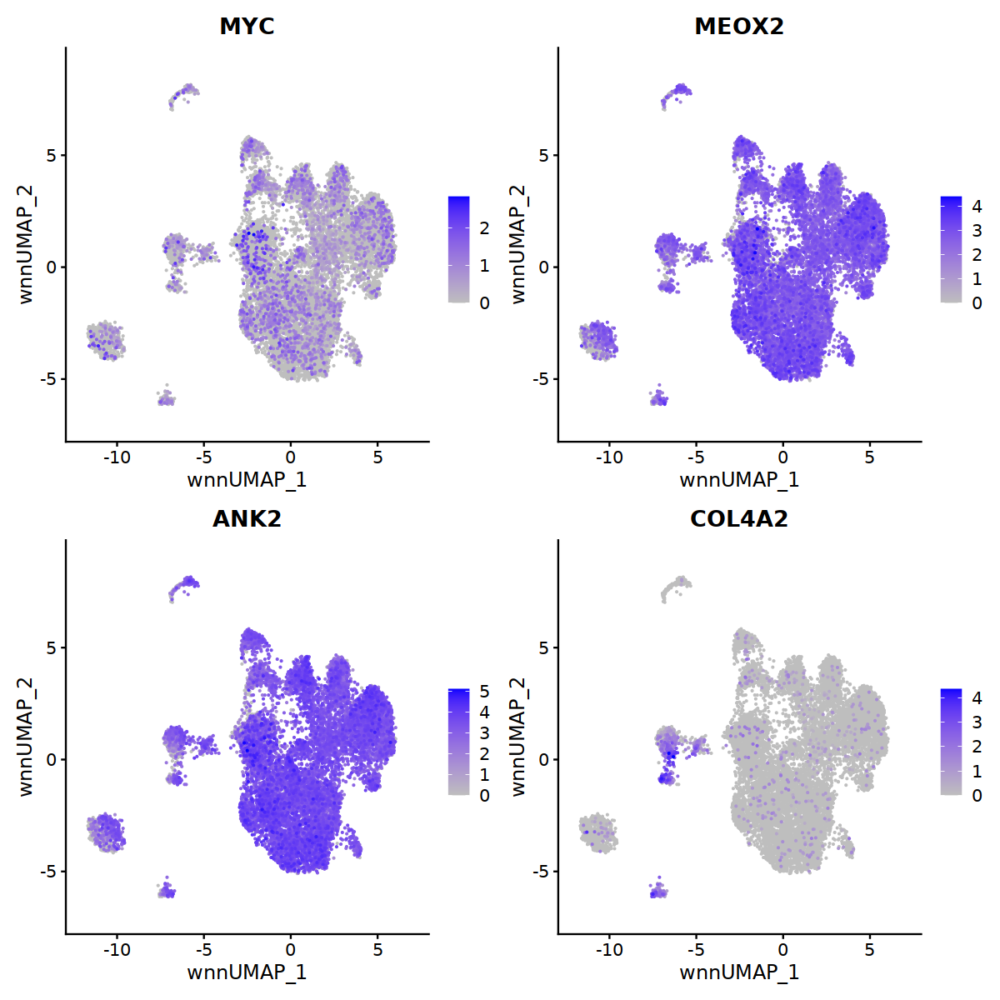

In [11]:
options(repr.plot.width = 10, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("MYC","MEOX2", "ANK2", "COL4A2"),ncol=2,
            cols = c("gray", "blue"),  order=T)

## Re-normalize

In [12]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

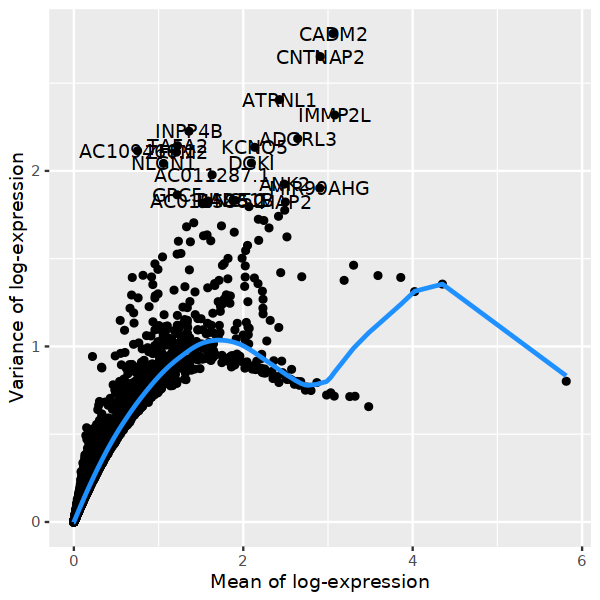

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 7387
[1] 7368


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  DPYD, PLXDC2, ZEB2, LRMDA, TCF4, UBE2E2, ZSWIM6, ITPR2, FRMD4A, TRPS1 
	   DOCK4, MEF2C, SLC9A9, SLC8A1, RUNX1, TNS3, ATXN1, ELMO1, ARHGAP18, CHST11 
	   FMNL2, LDLRAD4, IFI16, DOCK10, SFMBT2, PSD3, BNC2, MIR181A1HG, TANC2, ARHGAP26 
Negative:  MPPED2, SEMA3D, BMP5, BACH2, FGFR1, EPHA3, SEMA3C, MIR100HG, PALLD, L3MBTL4 
	   CDK14, SHROOM3, AL390957.1, AC092957.1, COL19A1, NTNG1, NFIB, UNC5C, AC011287.1, EPHA7 
	   NPAS3, SEMA6D, PDE3A, WIF1, SYNE2, OLFM3, PCDH7, PRICKLE2, LGR4, GPC5 
PC_ 2 
Positive:  MS4A6A, CD163, FMN1, SLCO2B1, MERTK, DOCK2, F13A1, PTPRC, SAMSN1, C1QB 
	   FYB1, LNCAROD, FCGR2A, C1QA, CYBB, TBXAS1, MS4A7, AOAH, MRC1, CD163L1 
	   SLC9A9, MS4A4A, MARCH1, DAPK1, TLR2, KYNU, C1QC, MTSS1, DOCK4, CSF1R 
Negative:  COL6A3, PRRX1, DLC1, IGFBP7, COL1A1, SULF1, SPARC, EDIL3, BICC1, POSTN 
	   COL6A1, RBMS3, COL12A1, BGN, COL4A2, CDH11, CACNA1C, FN1, COL4A1, SLIT2 
	   THBS2, CFH, COL6A2, FAP, FSTL1, TSHZ2, LHFPL6, VCAN, CO

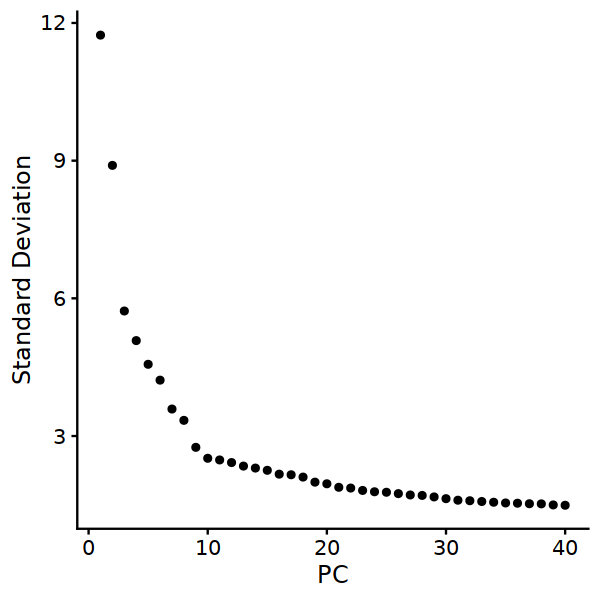

In [19]:
ElbowPlot(seurat_obj, n=40)

In [20]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


16:10:36 UMAP embedding parameters a = 0.9922 b = 1.112

16:10:36 Read 14421 rows and found 20 numeric columns

16:10:36 Using Annoy for neighbor search, n_neighbors = 30

16:10:36 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:10:38 Writing NN index file to temp file /scratch_tmp/49729482/RtmpJU0qk8/file974a1e693917

16:10:38 Searching Annoy index using 1 thread, search_k = 3000

16:10:42 Annoy recall = 98.64%

16:10:43 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

16:10:43 241 smooth knn distance failures

16:10:45 Initializing from normalized Laplacian + noise (using irlba)

16:10:46 Commencing optimization for 200 epochs, with 607810 positive edges

16:11:04 Optimizatio

In [21]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [22]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

16:11:45 UMAP embedding parameters a = 0.9922 b = 1.112

16:11:45 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

16:11:46 229 smooth knn distance failures

16:11:47 Initializing from normalized Laplacian + noise (using irlba)

16:11:48 Commencing optimization for 200 epochs, with 439046 positive edges

16:12:07 Optimization finished



In [23]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 14421
Number of edges: 551035

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9817
Number of communities: 11
Elapsed time: 1 seconds


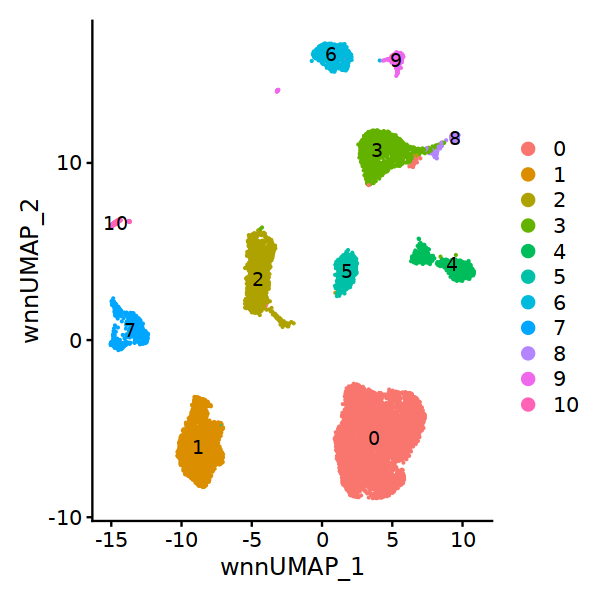

In [24]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

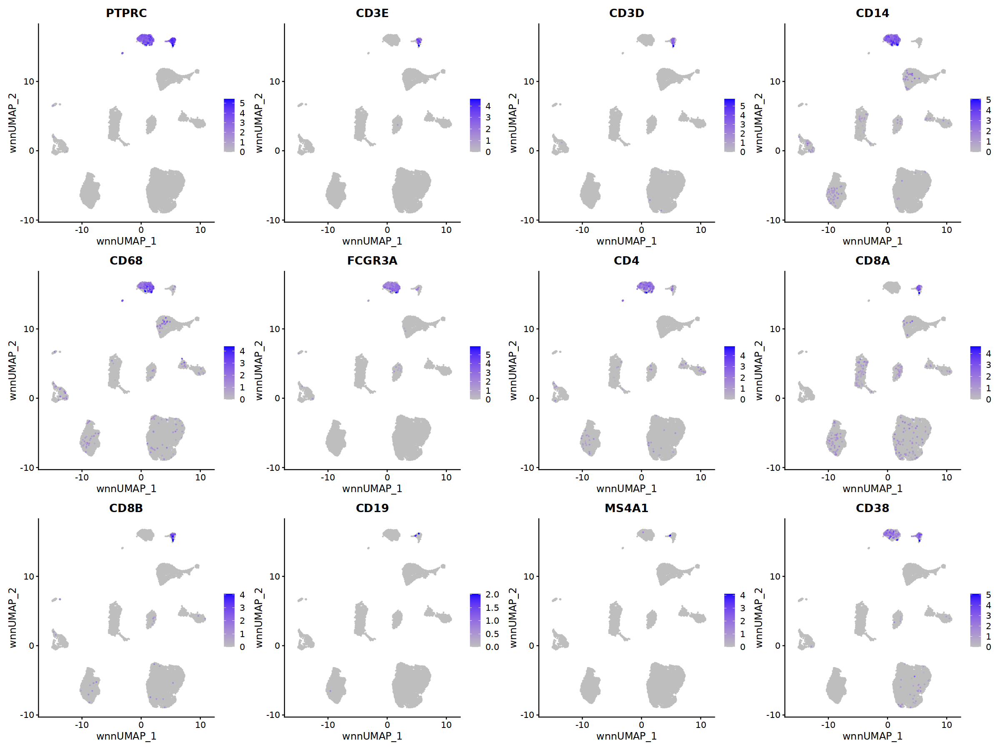

In [25]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

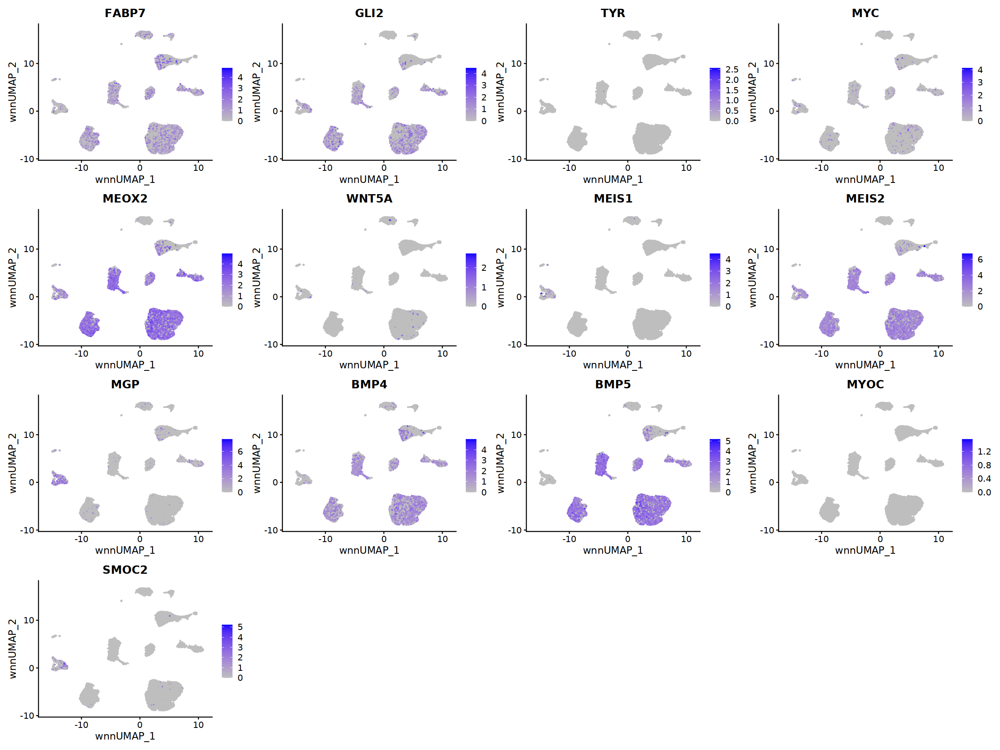

In [26]:
options(repr.plot.width = 20, repr.plot.height = 15)
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

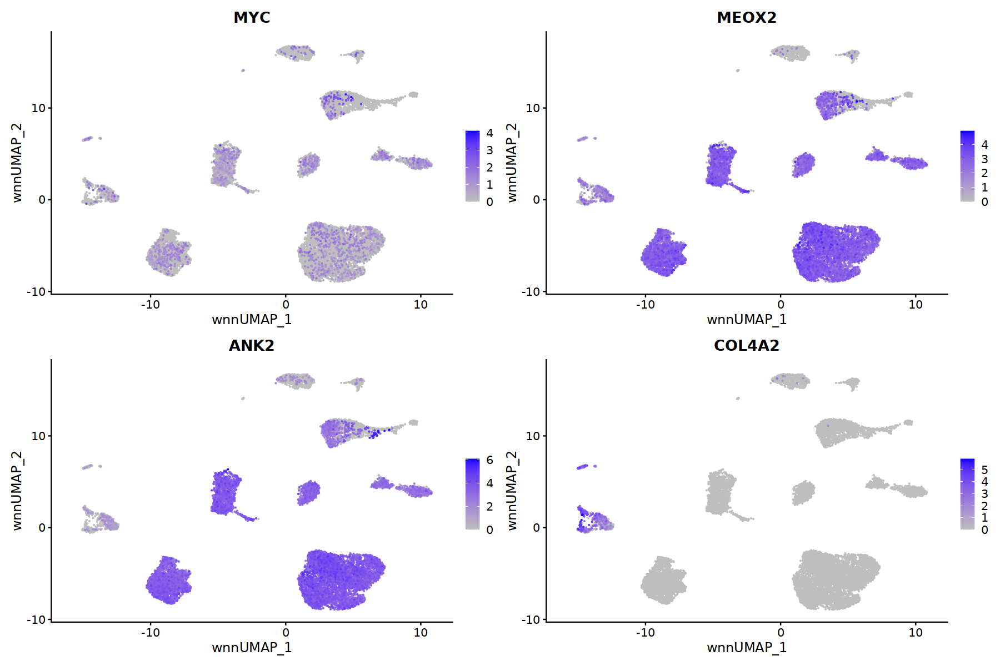

In [27]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("MYC","MEOX2", "ANK2", "COL4A2"),ncol=2,
            cols = c("gray", "blue"),  order=T)

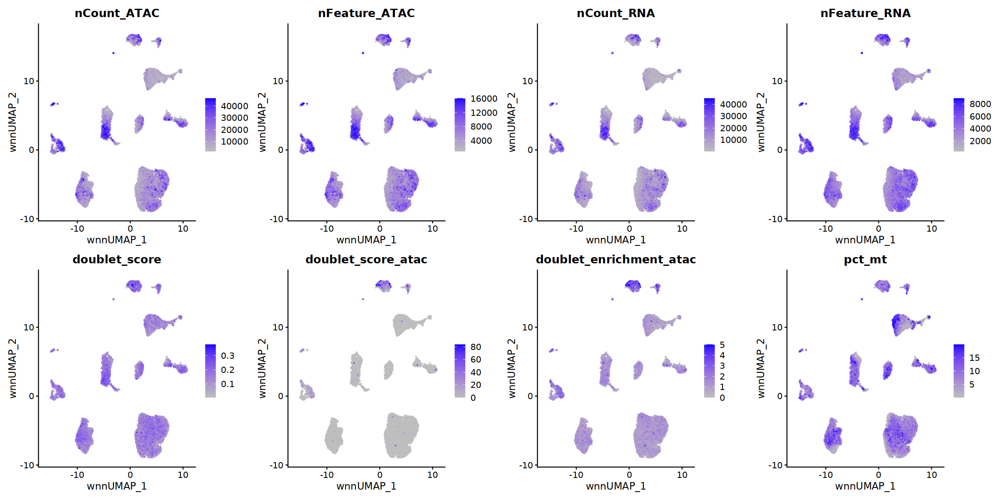

In [28]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

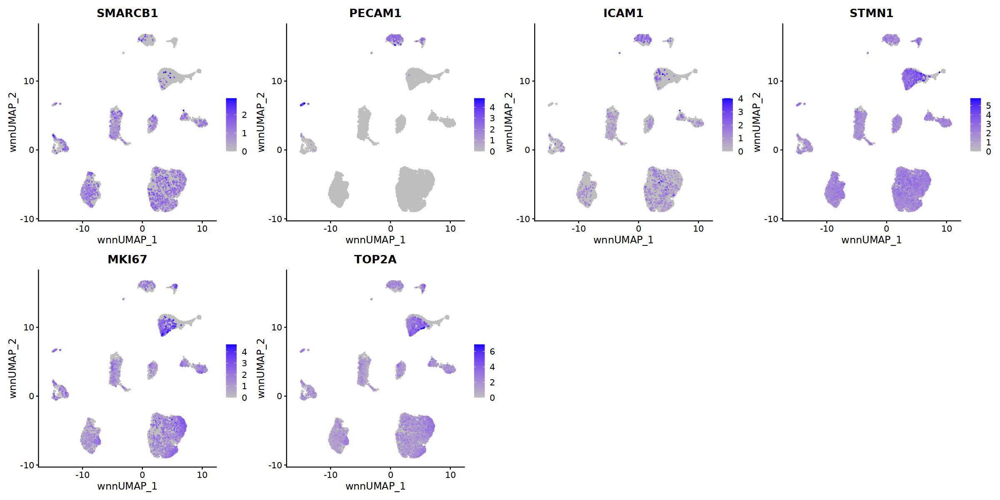

In [29]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [30]:
rna.markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, 
                              min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10



In [31]:
rna.markers %>% 
  dplyr::filter(cluster == "3") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=15)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CENPF,4.384881e-17,2.524153,0.394,0.402,1.378826e-12,3,CENPF
TOP2A,3.084170e-16,2.155455,0.346,0.322,9.698174e-12,3,TOP2A
LGALS1,9.318217e-202,1.845686,0.799,0.889,2.930113e-197,3,LGALS1
RPL23A,1.032206e-266,1.810923,0.851,0.917,3.245772e-262,3,RPL23A
RPL26,0.000000e+00,1.779413,0.928,0.965,0.000000e+00,3,RPL26
HMGB2,3.648402e-08,1.764210,0.331,0.354,1.147240e-03,3,HMGB2
RPL37,1.036210e-267,1.753616,0.855,0.930,3.258361e-263,3,RPL37
RPS27,3.533392e-115,1.742961,0.726,0.828,1.111075e-110,3,RPS27
RPS11,1.223612e-258,1.731070,0.844,0.921,3.847649e-254,3,RPS11


In [32]:
rna.markers %>% 
  dplyr::filter(cluster == "8") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=15)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
RPL321,1.151965e-90,2.553459,0.129,0.966,3.622353e-86,8,RPL32
PTPRG1,7.812143e-14,2.552676,0.004,0.180,2.456528e-09,8,PTPRG
RPS181,1.053549e-68,2.423008,0.188,0.991,3.312886e-64,8,RPS18
VIM1,2.782063e-66,2.398241,0.195,0.995,8.748197e-62,8,VIM
RPL13A1,1.421913e-84,2.254283,0.147,0.979,4.471206e-80,8,RPL13A
RPL191,3.061888e-112,2.128593,0.085,0.961,9.628106e-108,8,RPL19
MGP2,1.034038e-08,1.964733,0.004,0.115,3.251532e-04,8,MGP
RPL411,4.142846e-90,1.951015,0.136,0.980,1.302718e-85,8,RPL41
RPS111,3.923095e-112,1.716851,0.070,0.930,1.233617e-107,8,RPS11


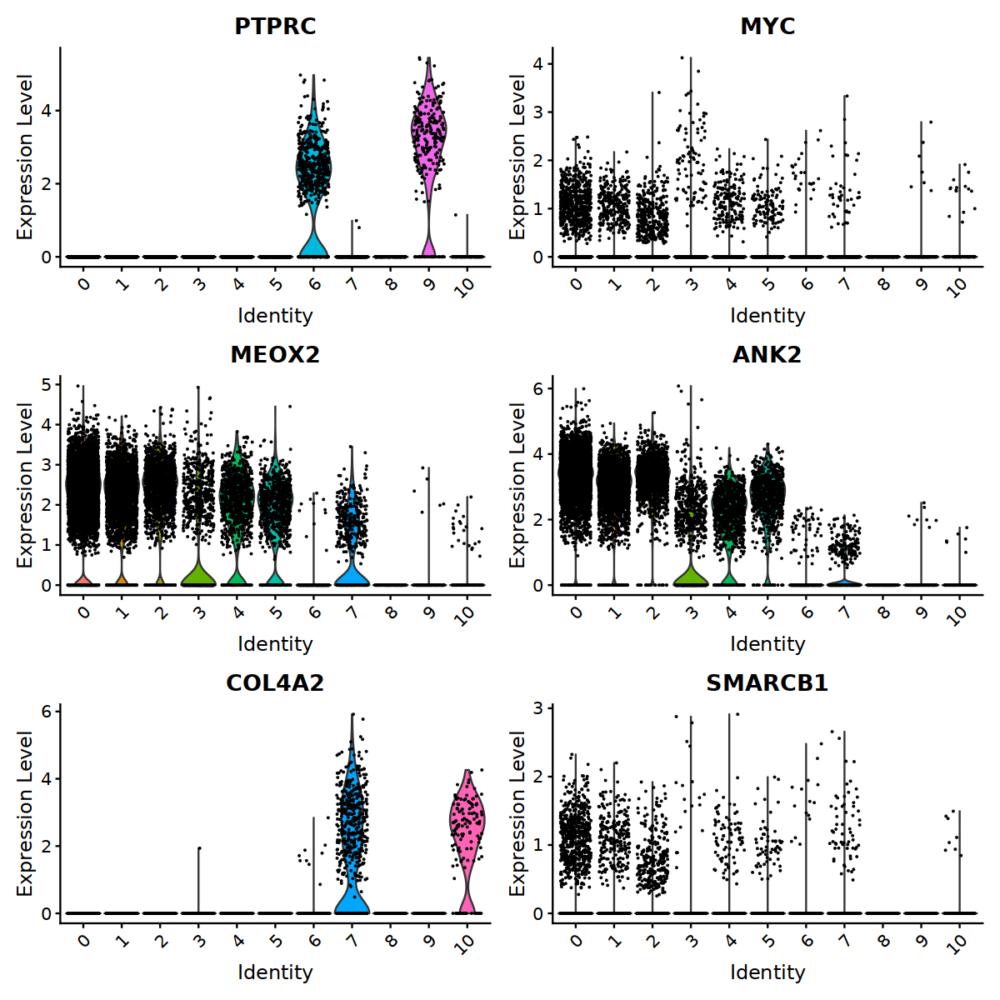

In [33]:
options(repr.plot.width = 10, repr.plot.height = 10)
VlnPlot(seurat_obj, 
            feature=c("PTPRC", "MYC","MEOX2", "ANK2", "COL4A2", "SMARCB1"),ncol=2)

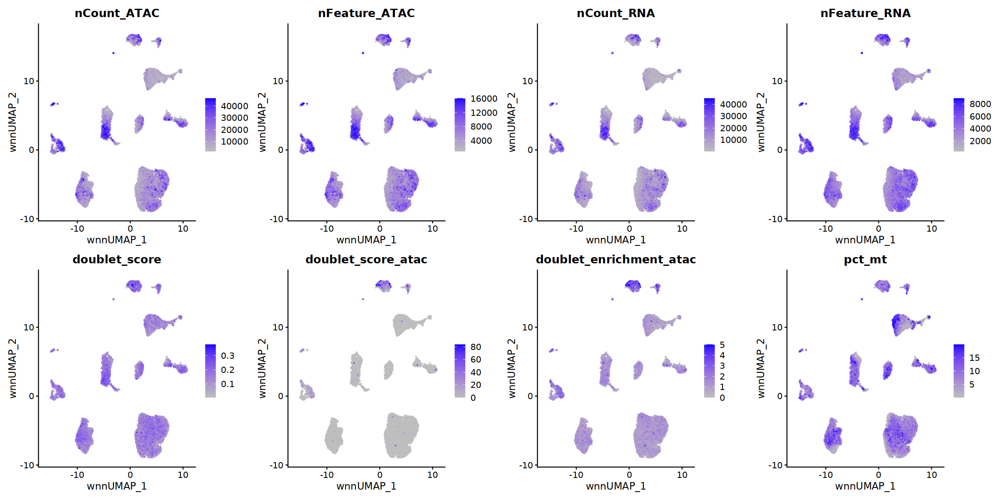

In [34]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

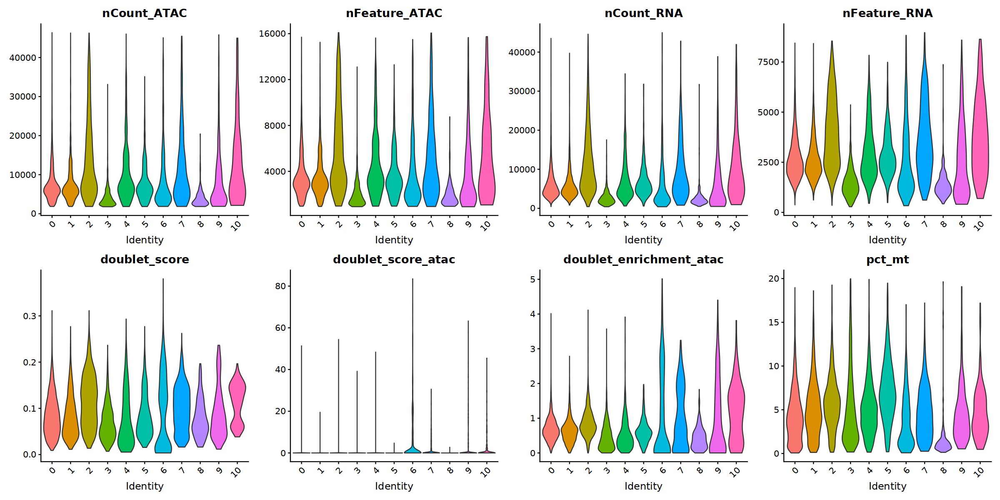

In [35]:
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4, pt.size = 0)

## Filter cells

low quality cells

In [36]:
seurat_obj <- subset(seurat_obj, idents = c("3", "8"), invert = TRUE)

In [37]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [38]:
keep_peaks <- data.frame(rowSums(as.matrix(seurat_obj[['ATAC']]@counts)) >= 1)
colnames(keep_peaks) <- "logical"
keep_peaks <- subset(keep_peaks, logical==TRUE)
seurat_obj[['ATAC']]@counts <- seurat_obj[['ATAC']]@counts[rownames(keep_peaks), ]
seurat_obj[['ATAC']]@data <- seurat_obj[['ATAC']]@data[rownames(keep_peaks), ]

### RNA

In [39]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [40]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

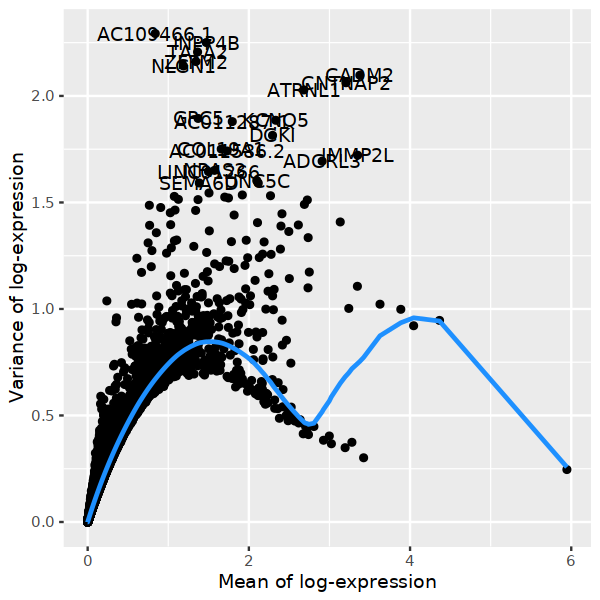

In [41]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [42]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 3408
[1] 3389


In [43]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  MPPED2, SEMA3D, EPHA3, FGFR1, BMP5, MIR100HG, CDK14, BACH2, PALLD, SEMA3C 
	   L3MBTL4, NFIB, SHROOM3, AL390957.1, UNC5C, AC092957.1, PDE3A, NTNG1, COL19A1, AC011287.1 
	   EPHA7, NPAS3, WIF1, SYNE2, SEMA6D, PCDH7, MAGI1, LINC01266, SGO1-AS1, GPC5 
Negative:  DPYD, PLXDC2, ZEB2, LRMDA, ZSWIM6, TCF4, ITPR2, UBE2E2, DOCK4, TRPS1 
	   FRMD4A, SLC9A9, MEF2C, SLC8A1, RUNX1, ELMO1, ARHGAP18, TNS3, CHST11, FMNL2 
	   ATXN1, LDLRAD4, SFMBT2, DOCK10, IFI16, PSD3, ARHGAP26, MIR181A1HG, GAB2, TANC2 
PC_ 2 
Positive:  MS4A6A, CD163, FMN1, SLCO2B1, MERTK, DOCK2, F13A1, PTPRC, C1QB, C1QA 
	   FYB1, SAMSN1, FCGR2A, LNCAROD, CYBB, TBXAS1, MS4A7, AOAH, CD163L1, MRC1 
	   MARCH1, MS4A4A, SLC9A9, C1QC, DAPK1, TLR2, KYNU, MTSS1, CSF1R, SYK 
Negative:  COL6A3, IGFBP7, PRRX1, DLC1, COL1A1, SPARC, SULF1, POSTN, EDIL3, COL6A1 
	   BICC1, COL12A1, RBMS3, BGN, COL4A2, FN1, COL4A1, CACNA1C, CDH11, THBS2 
	   SLIT2, CFH, COL6A2, FAP, FSTL1, VCAN, LHFPL6, COL5A1

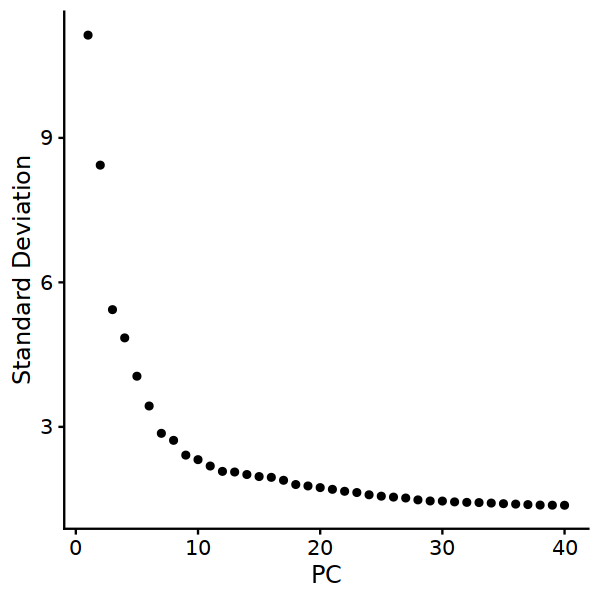

In [44]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [45]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [46]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



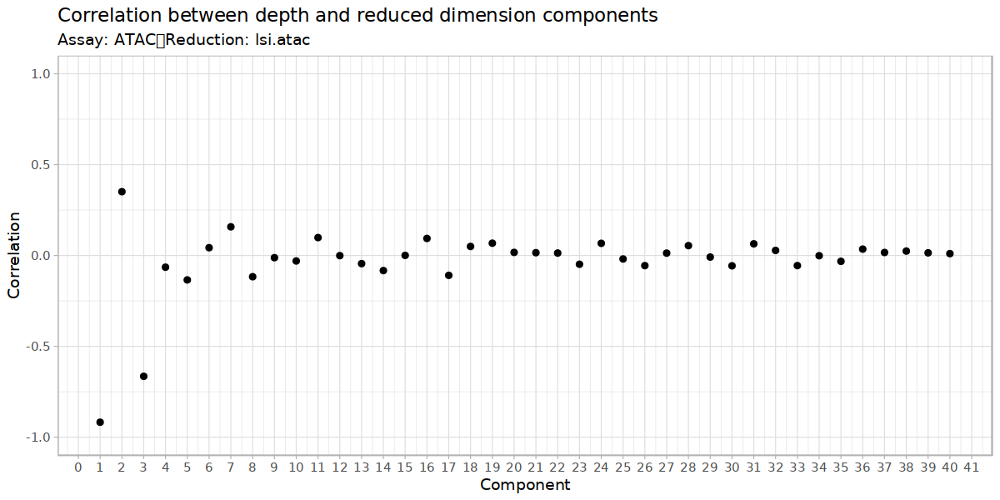

In [47]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

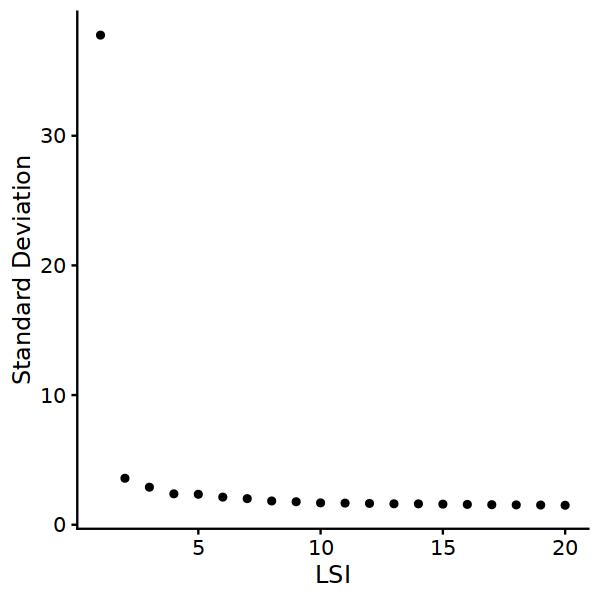

In [48]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [49]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [50]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

16:21:26 UMAP embedding parameters a = 0.115 b = 1.929

16:21:27 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

16:21:29 Initializing from normalized Laplacian + noise (using irlba)

16:21:29 Commencing optimization for 200 epochs, with 382488 positive edges

16:21:46 Optimization finished



In [51]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 12724
Number of edges: 453242

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9798
Number of communities: 9
Elapsed time: 1 seconds


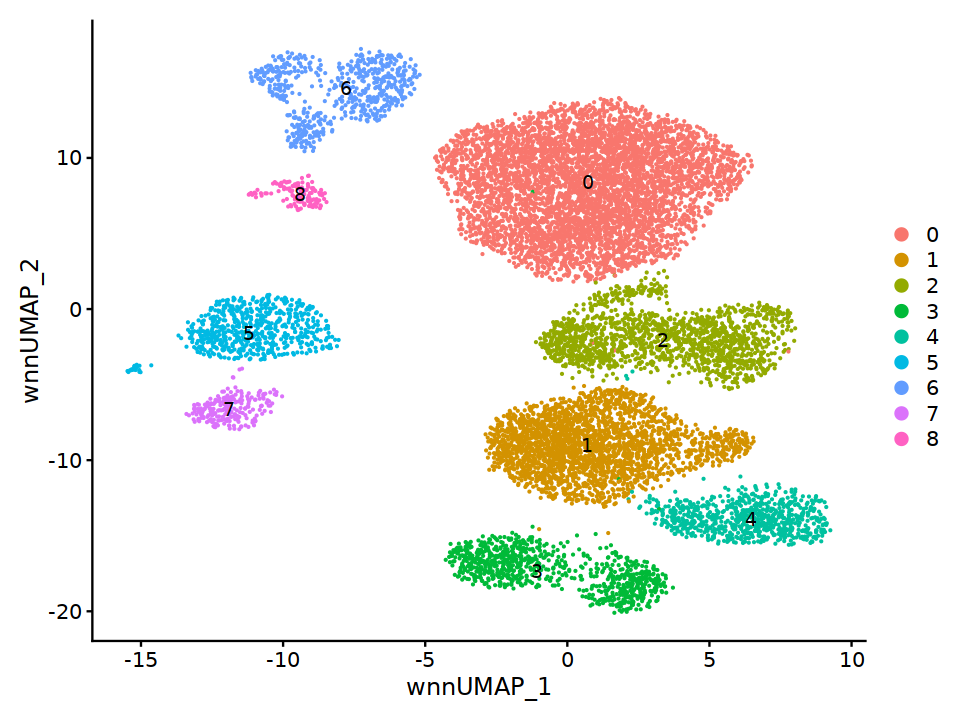

In [52]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

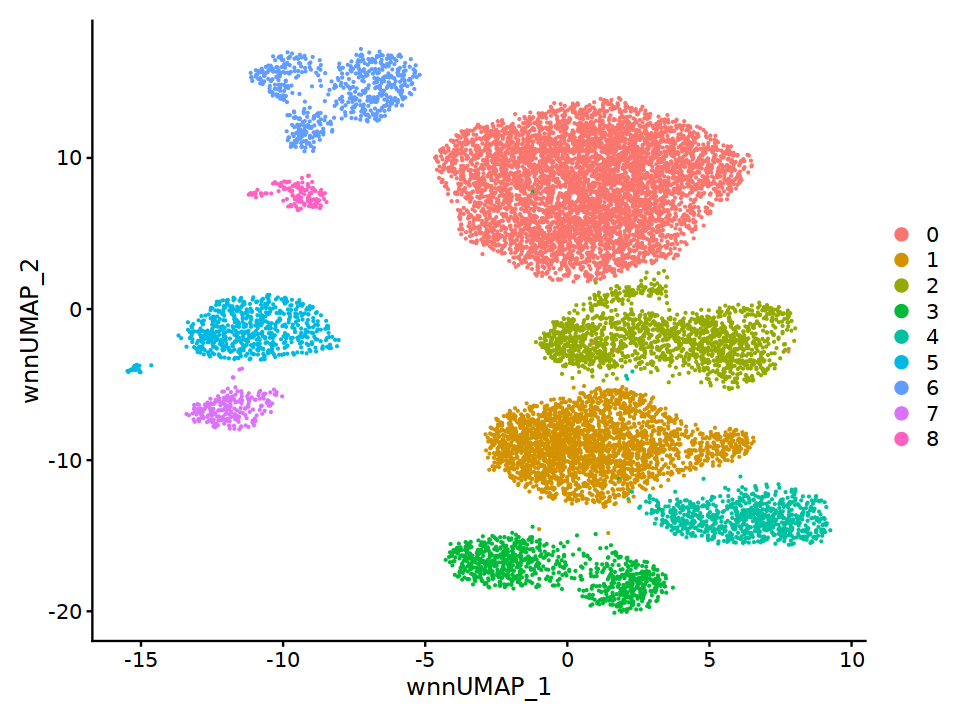

In [53]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap") 

In [54]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8



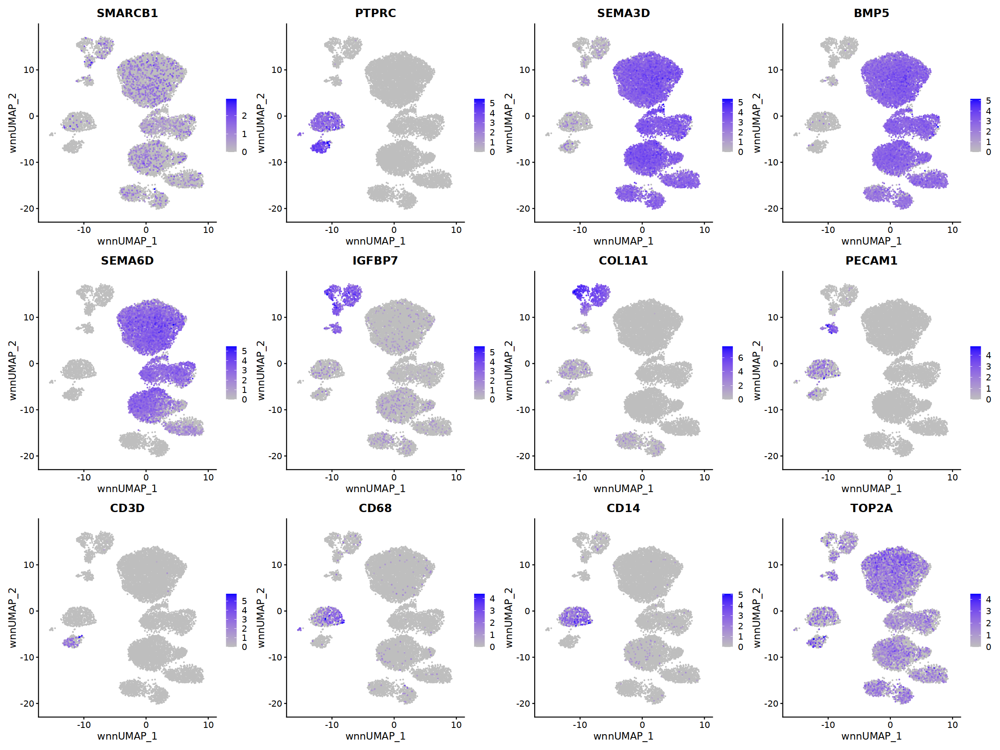

In [55]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC","SEMA3D", "BMP5","SEMA6D", 
                              "IGFBP7", "COL1A1", "PECAM1","CD3D","CD68","CD14",
                              "TOP2A"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),order=T)

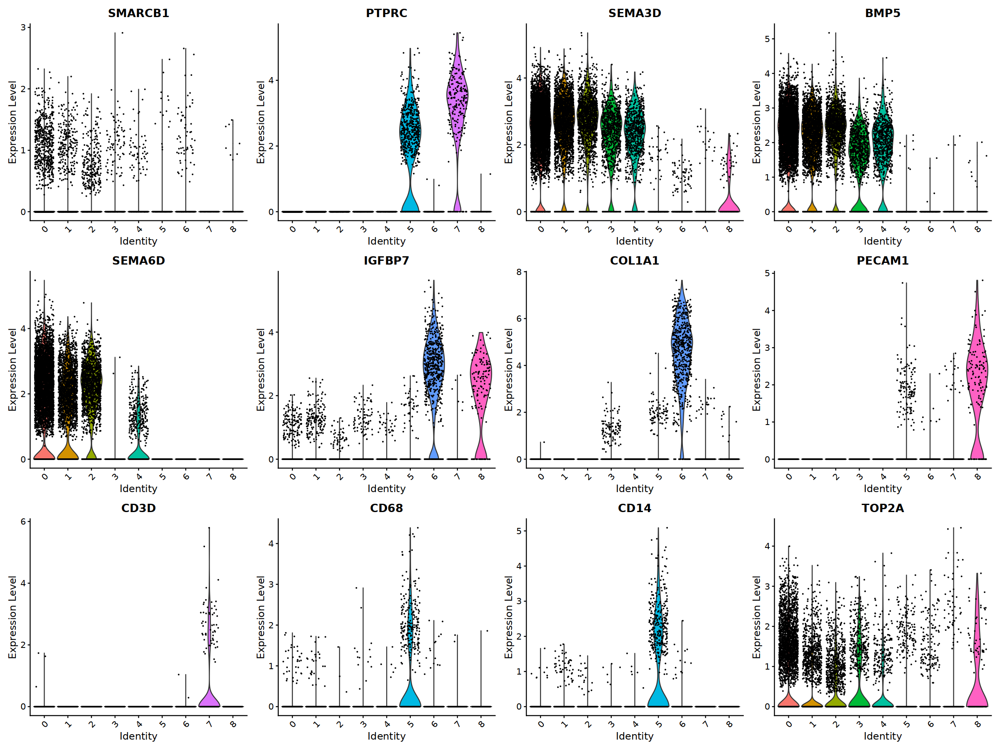

In [56]:
VlnPlot(seurat_obj, feature=vars2plot)

In [57]:
rna.markers %>% 
  dplyr::filter(cluster == "8") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=25)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
PLCB11,0.000000e+00,5.337683,0.923,0.017,0.000000e+00,8,PLCB1
LDB21,0.000000e+00,5.014542,0.915,0.017,0.000000e+00,8,LDB2
TCF42,0.000000e+00,4.533621,0.962,0.063,0.000000e+00,8,TCF4
CALCRL1,0.000000e+00,4.526155,0.892,0.024,0.000000e+00,8,CALCRL
GRB101,0.000000e+00,4.500634,0.854,0.007,0.000000e+00,8,GRB10
PTPRM2,0.000000e+00,4.228377,0.892,0.058,0.000000e+00,8,PTPRM
PLPP11,1.323157e-115,4.187959,0.846,0.191,4.144261e-111,8,PLPP1
ARL152,2.429718e-82,4.184472,0.923,0.400,7.610121e-78,8,ARL15
FLT1,0.000000e+00,4.050725,0.777,0.001,0.000000e+00,8,FLT1


### Rename

In [58]:
rename_clusters <- c("0"="Tumor TAFA2",
                     "1"="Tumor LRRC7",
                     "2"="Tumor SGCZ", 
                     "3"="Tumor NRG1",
                     "4"="Tumor SOX6",
                     "5"="Monocytes-Macrophages", 
                     "6"="Fibroblast",
                     "7"="T-cells",
                     "8"="Endothelial cells")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [59]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight','nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [60]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [61]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [62]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [63]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Other stromal

Calculating cluster Immune



In [64]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

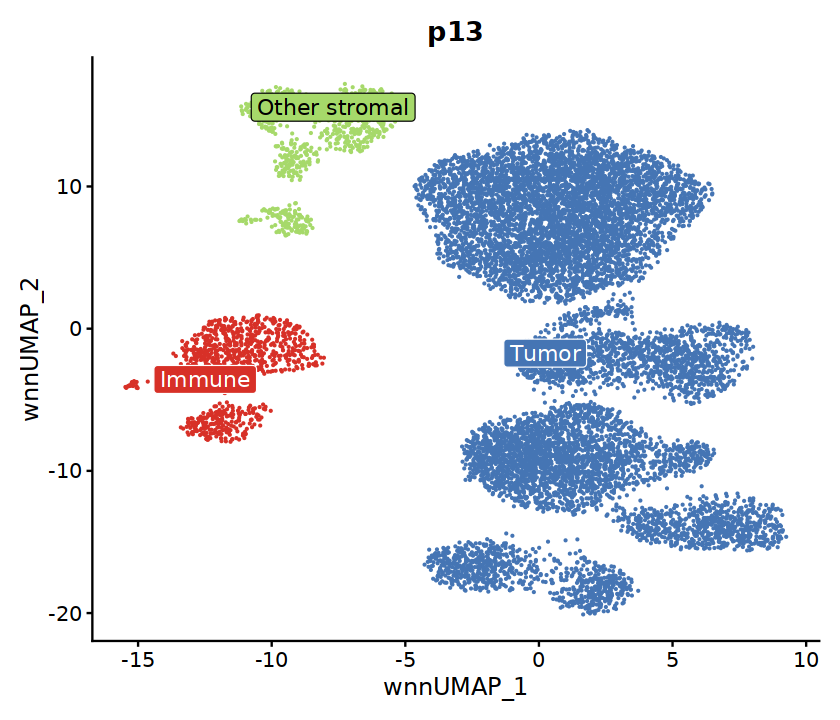

In [65]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [66]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [67]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [68]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

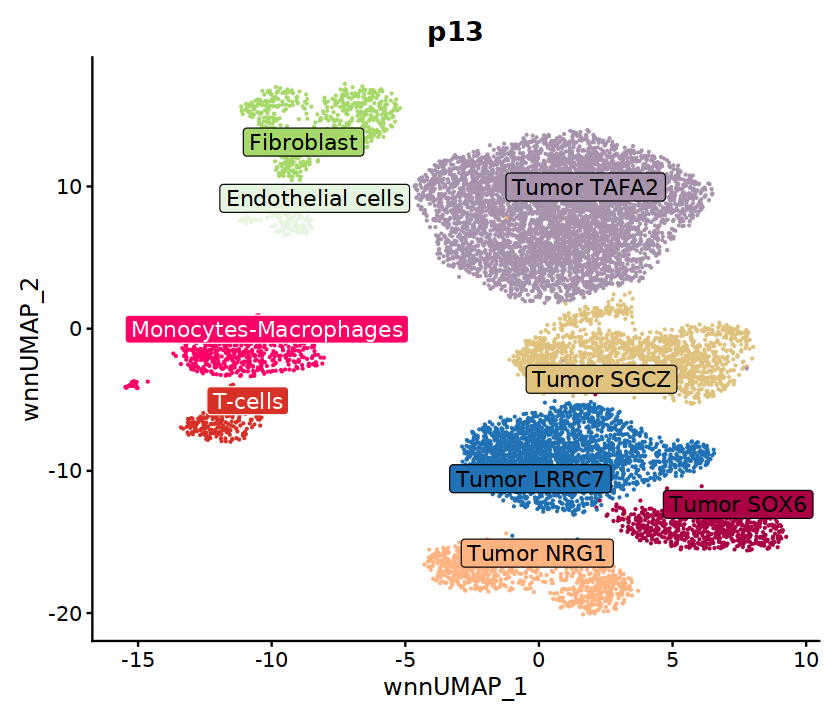

In [69]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [70]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

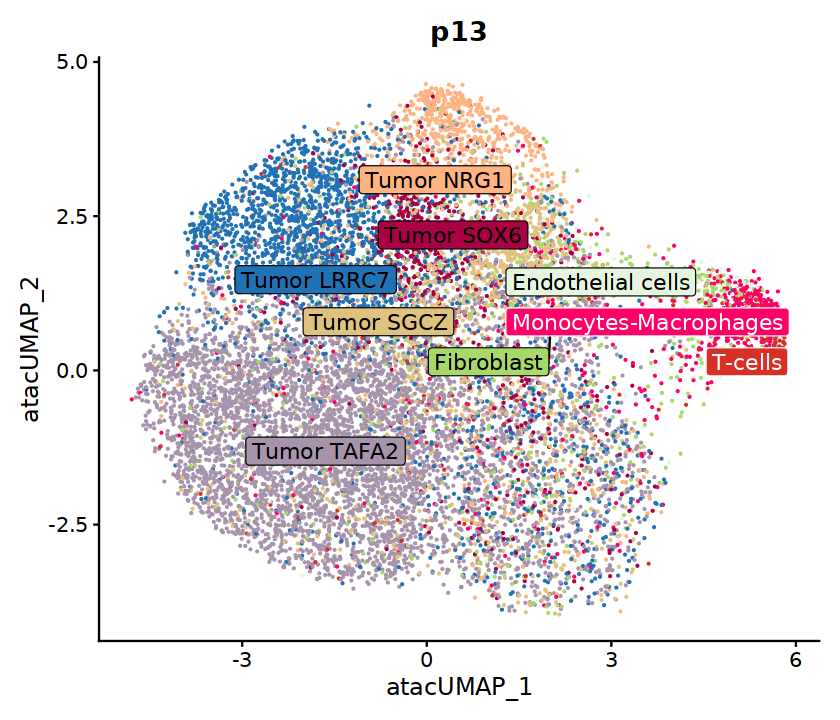

In [71]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [72]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

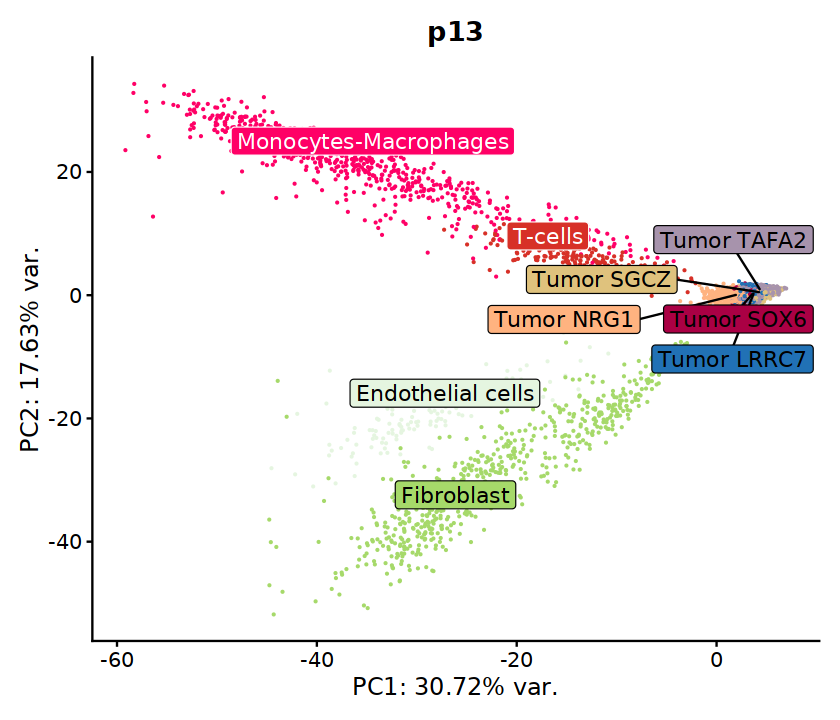

In [73]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

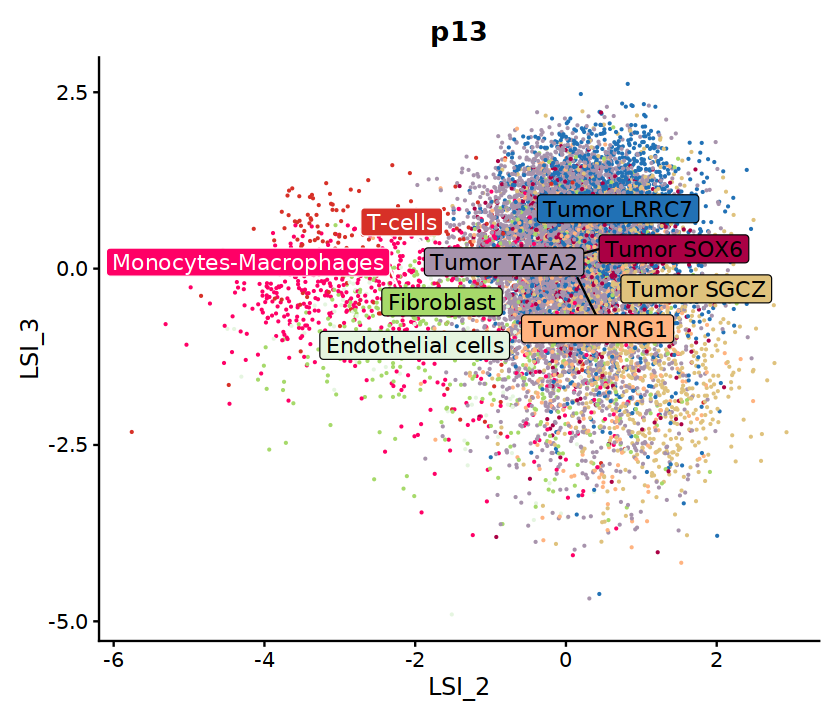

In [74]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

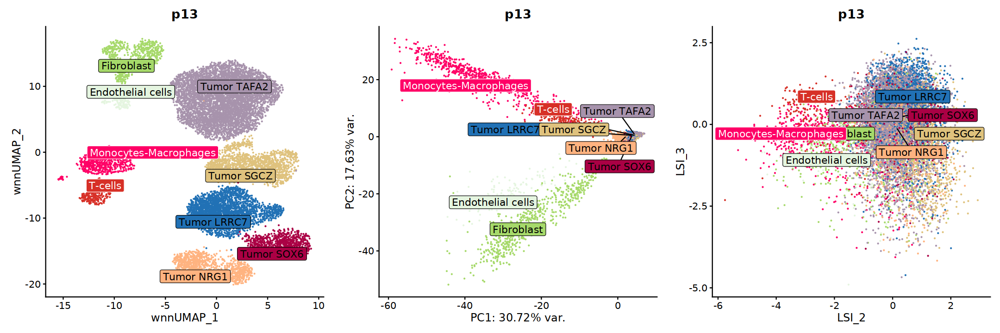

In [75]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [76]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [77]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("BMP5", "MEOX2", "ANK2", "FGFR1"), markers) ## common markers to all clusters

In [78]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

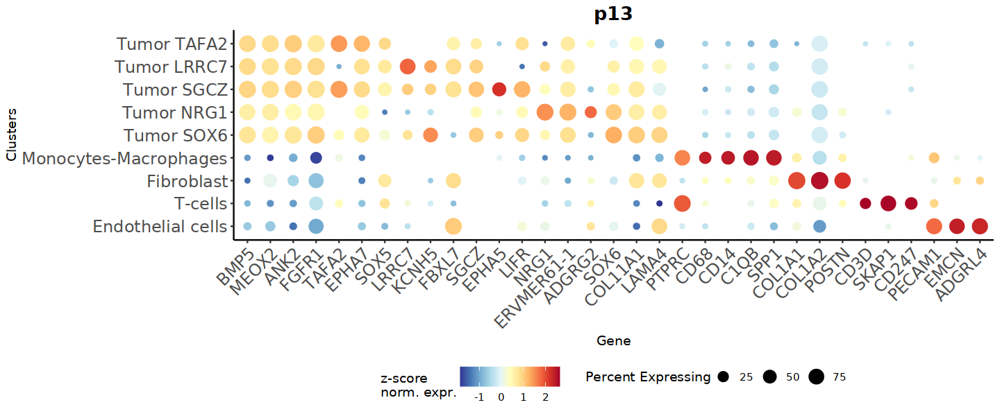

In [79]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

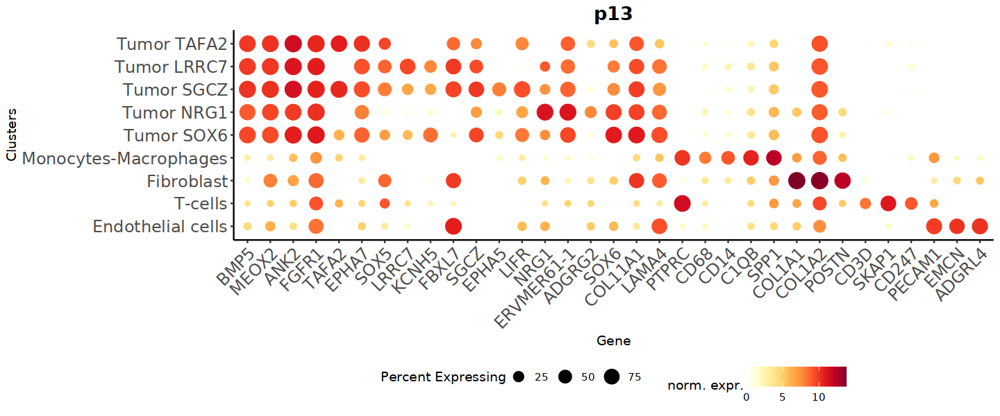

In [80]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [81]:
ggsave(plot = dp1, width = 12, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save

In [82]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [83]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [84]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [85]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    